
Lineage1: 25678 клеток
AB_CD14      | r =  0.176 | p = 3.49e-178
AB_CD16      | r = -0.058 | p = 1.64e-20
AB_CX3CR1    | r =  0.064 | p = 9.96e-25
AB_CD163     | r =  0.089 | p = 1.25e-46
AB_HLA-DR    | r =  0.227 | p = 1.92e-298
AB_CD64      | r =  0.079 | p = 1.29e-36
AB_CD83      | r = -0.104 | p = 1.05e-62
AB_SIGLEC1   | r = -0.008 | p = 1.73e-01


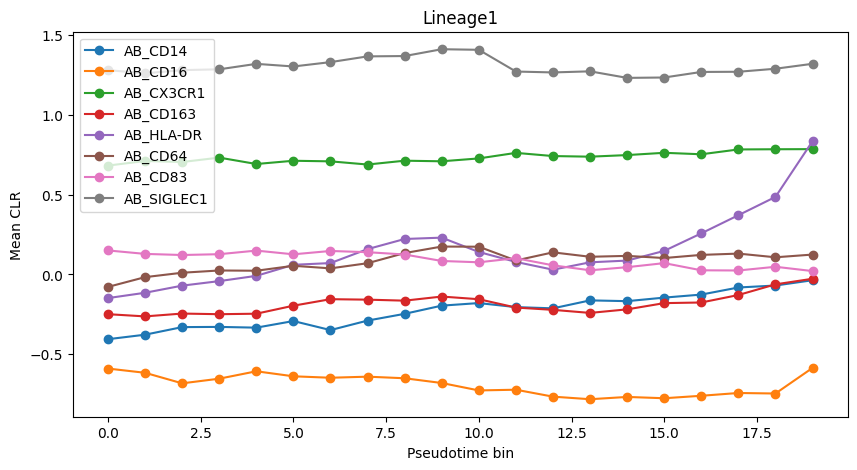


Lineage2: 19041 клеток
AB_CD14      | r =  0.013 | p = 7.73e-02
AB_CD16      | r =  0.326 | p = 0.00e+00
AB_CX3CR1    | r =  0.253 | p = 6.19e-276
AB_CD163     | r =  0.107 | p = 9.25e-50
AB_HLA-DR    | r =  0.434 | p = 0.00e+00
AB_CD64      | r = -0.096 | p = 6.61e-40
AB_CD83      | r = -0.065 | p = 3.86e-19
AB_SIGLEC1   | r = -0.020 | p = 5.74e-03


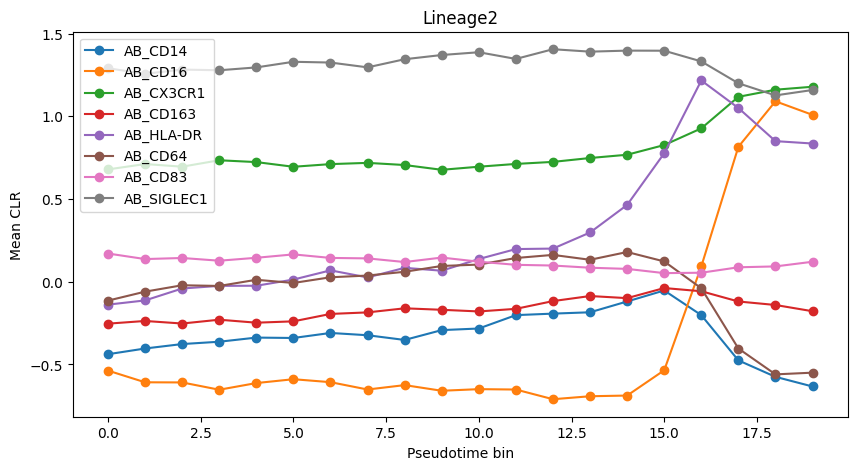

In [ ]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr
from scipy.sparse import issparse
import matplotlib.pyplot as plt

adata = sc.read_h5ad('../data_bio/covid_mono_prot.h5ad')
df_pt = pd.read_csv('../data_bio/slingshot_pseudotime_all_lineages_excluded.csv', index_col='cell_id')

proteins = ['AB_CD14', 'AB_CD16', 'AB_CX3CR1', 'AB_CD163',
            'AB_HLA-DR', 'AB_CD64', 'AB_CD83', 'AB_SIGLEC1']
valid_proteins = [p for p in proteins if p in adata.var_names]

X = adata.layers['raw']
X = X.toarray() if issparse(X) else np.asarray(X)
logX = np.log1p(X)
clr = logX - logX.mean(axis=1, keepdims=True)
df_all = pd.DataFrame(clr, columns=adata.var_names, index=adata.obs_names)

for lin in ['Lineage1', 'Lineage2']:
    d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
    print(f"\n{lin}: {len(d)} клеток")
    for prot in valid_proteins:
        r, p = spearmanr(d[lin], d[prot])
        print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

    d['bin'] = pd.qcut(d[lin], q=20, labels=False)
    d.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o', title=lin)
    plt.xlabel('Pseudotime bin')
    plt.ylabel('Mean CLR')
    plt.show()

9921 full_clustering
CD14_mono         5806
CD16_mono         3281
C1_CD16_mono       834
CD83_CD14_mono       0
Mono_prolif          0
Name: count, dtype: int64
AB_CD14      | r = -0.152 | p = 2.56e-52
AB_CD16      | r =  0.539 | p = 0.00e+00
AB_CX3CR1    | r =  0.377 | p = 0.00e+00
AB_CD163     | r =  0.023 | p = 2.45e-02
AB_HLA-DR    | r =  0.415 | p = 0.00e+00
AB_CD64      | r = -0.306 | p = 9.24e-214
AB_CD83      | r = -0.026 | p = 1.10e-02
AB_SIGLEC1   | r = -0.160 | p = 7.17e-58


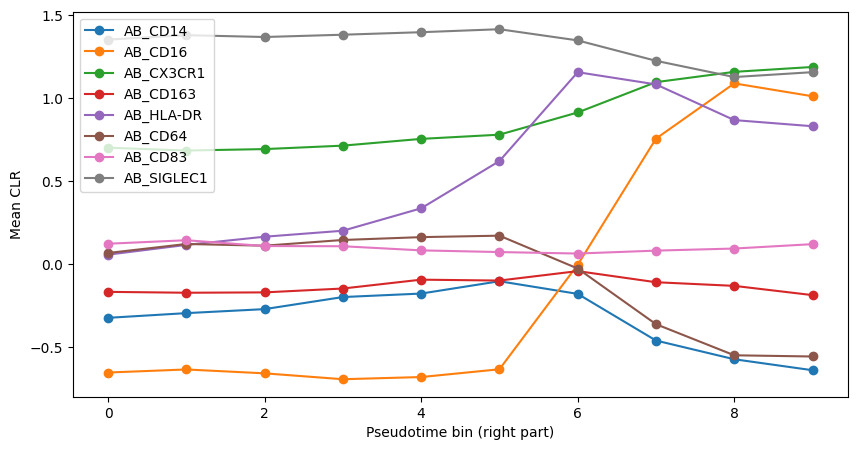

C1_CD16_mono 863 {'AB_CD16': np.float64(0.546), 'AB_CD14': np.float64(-0.203), 'AB_CX3CR1': np.float64(0.336)}
CD16_mono 3469 {'AB_CD16': np.float64(0.381), 'AB_CD14': np.float64(-0.258), 'AB_CX3CR1': np.float64(0.2)}


In [4]:
lin = 'Lineage2'
d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
d = d.join(adata.obs['full_clustering'])

d = d[d['full_clustering'].isin(['CD14_mono', 'C1_CD16_mono', 'CD16_mono'])]
d['bin'] = pd.qcut(d[lin], q=20, labels=False)

cut = d.loc[d['full_clustering'].isin(['C1_CD16_mono', 'CD16_mono']), lin].quantile(0.05)
dr = d[d[lin] >= cut]
print(len(dr), dr['full_clustering'].value_counts())

for prot in valid_proteins:
    r, p = spearmanr(dr[lin], dr[prot])
    print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

dr = dr.copy()
dr['bin'] = pd.qcut(dr[lin], q=10, labels=False)
dr.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o')
plt.xlabel('Pseudotime bin (right part)')
plt.ylabel('Mean CLR')
plt.show()

for cl in ['C1_CD16_mono', 'CD16_mono']:
    s = d[d['full_clustering'] == cl]
    print(cl, len(s), {p: round(spearmanr(s[lin], s[p])[0], 3) for p in ['AB_CD16', 'AB_CD14', 'AB_CX3CR1']})

And the ground truth without exclusion:


Lineage1: 20706 клеток
AB_CD14      | r =  0.017 | p = 1.54e-02
AB_CD16      | r =  0.335 | p = 0.00e+00
AB_CX3CR1    | r =  0.263 | p = 0.00e+00
AB_CD163     | r =  0.094 | p = 5.90e-42
AB_HLA-DR    | r =  0.456 | p = 0.00e+00
AB_CD64      | r = -0.122 | p = 2.02e-69
AB_CD83      | r = -0.052 | p = 8.93e-14
AB_SIGLEC1   | r = -0.056 | p = 4.35e-16


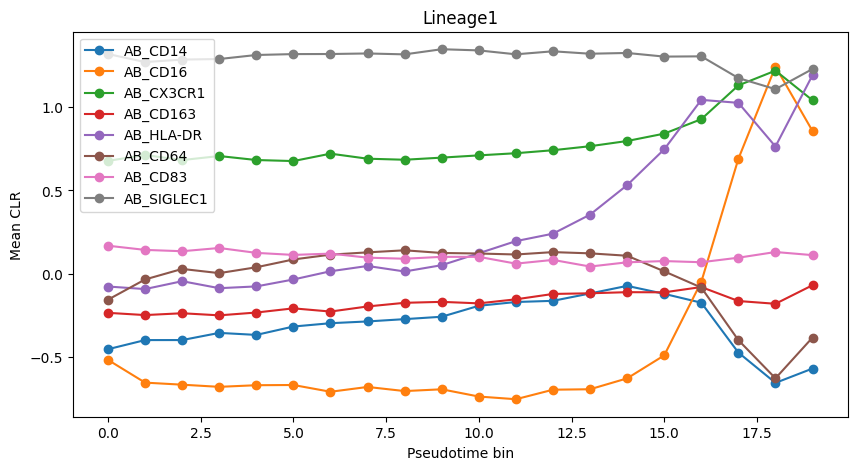


Lineage2: 25566 клеток
AB_CD14      | r =  0.166 | p = 1.43e-157
AB_CD16      | r = -0.051 | p = 2.27e-16
AB_CX3CR1    | r =  0.070 | p = 1.89e-29
AB_CD163     | r =  0.045 | p = 8.09e-13
AB_HLA-DR    | r =  0.144 | p = 2.39e-118
AB_CD64      | r =  0.062 | p = 4.27e-23
AB_CD83      | r = -0.084 | p = 7.83e-41
AB_SIGLEC1   | r = -0.009 | p = 1.62e-01


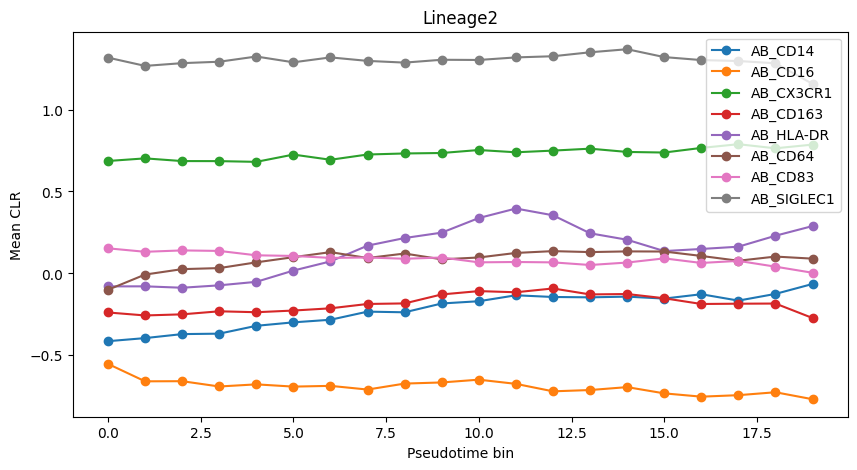

In [2]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr
from scipy.sparse import issparse
import matplotlib.pyplot as plt

adata = sc.read_h5ad('../data_bio/covid_mono_prot.h5ad')
df_pt = pd.read_csv('../data_bio/slingshot_pt_authors.csv', index_col='cell_id')

proteins = ['AB_CD14', 'AB_CD16', 'AB_CX3CR1', 'AB_CD163',
            'AB_HLA-DR', 'AB_CD64', 'AB_CD83', 'AB_SIGLEC1']
valid_proteins = [p for p in proteins if p in adata.var_names]

X = adata.layers['raw']
X = X.toarray() if issparse(X) else np.asarray(X)
logX = np.log1p(X)
clr = logX - logX.mean(axis=1, keepdims=True)
df_all = pd.DataFrame(clr, columns=adata.var_names, index=adata.obs_names)

for lin in ['Lineage1', 'Lineage2']:
    d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
    print(f"\n{lin}: {len(d)} клеток")
    for prot in valid_proteins:
        r, p = spearmanr(d[lin], d[prot])
        print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

    d['bin'] = pd.qcut(d[lin], q=20, labels=False)
    d.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o', title=lin)
    plt.xlabel('Pseudotime bin')
    plt.ylabel('Mean CLR')
    plt.show()

5106 full_clustering
CD16_mono         3269
CD14_mono          980
C1_CD16_mono       857
CD83_CD14_mono       0
Mono_prolif          0
Name: count, dtype: int64
AB_CD14      | r = -0.289 | p = 1.23e-98
AB_CD16      | r =  0.479 | p = 1.12e-290
AB_CX3CR1    | r =  0.209 | p = 1.50e-51
AB_CD163     | r =  0.000 | p = 9.89e-01
AB_HLA-DR    | r =  0.112 | p = 7.50e-16
AB_CD64      | r = -0.265 | p = 4.82e-83
AB_CD83      | r =  0.036 | p = 9.46e-03
AB_SIGLEC1   | r = -0.110 | p = 2.43e-15


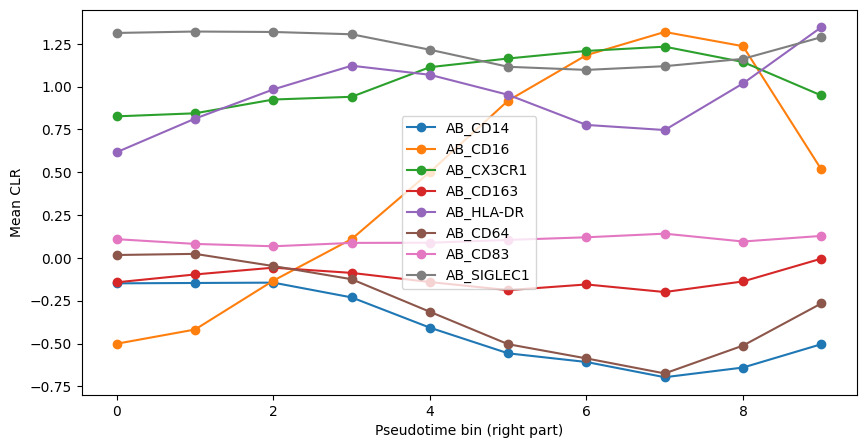

C1_CD16_mono 874 {'AB_CD16': np.float64(0.1), 'AB_CD14': np.float64(-0.125), 'AB_CX3CR1': np.float64(0.069)}
CD16_mono 3470 {'AB_CD16': np.float64(0.472), 'AB_CD14': np.float64(-0.292), 'AB_CX3CR1': np.float64(0.221)}


In [ ]:
lin = 'Lineage1'
d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
d = d.join(adata.obs['full_clustering'])

d = d[d['full_clustering'].isin(['CD14_mono', 'C1_CD16_mono', 'CD16_mono'])]
d['bin'] = pd.qcut(d[lin], q=20, labels=False)
lin = 'Lineage1'
d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
d = d.join(adata.obs['full_clustering'])

d = d[d['full_clustering'].isin(['CD14_mono', 'C1_CD16_mono', 'CD16_mono'])]
d['bin'] = pd.qcut(d[lin], q=20, labels=False)

cut = d.loc[d['full_clustering'].isin(['C1_CD16_mono', 'CD16_mono']), lin].quantile(0.05)
dr = d[d[lin] >= cut]
print(len(dr), dr['full_clustering'].value_counts())

for prot in valid_proteins:
    r, p = spearmanr(dr[lin], dr[prot])
    print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

dr = dr.copy()
dr['bin'] = pd.qcut(dr[lin], q=10, labels=False)
dr.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o')
plt.xlabel('Pseudotime bin (right part)')
plt.ylabel('Mean CLR')
plt.show()

for cl in ['C1_CD16_mono', 'CD16_mono']:
    s = d[d['full_clustering'] == cl]
    print(cl, len(s), {p: round(spearmanr(s[lin], s[p])[0], 3) for p in ['AB_CD16', 'AB_CD14', 'AB_CX3CR1']})
cut = d.loc[d['full_clustering'].isin(['C1_CD16_mono', 'CD16_mono']), lin].quantile(0.05)
dr = d[d[lin] >= cut]
print(len(dr), dr['full_clustering'].value_counts())

for prot in valid_proteins:
    r, p = spearmanr(dr[lin], dr[prot])
    print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

dr = dr.copy()
dr['bin'] = pd.qcut(dr[lin], q=10, labels=False)
dr.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o')
plt.xlabel('Pseudotime bin (right part)')
plt.ylabel('Mean CLR')
plt.show()

for cl in ['C1_CD16_mono', 'CD16_mono']:
    s = d[d['full_clustering'] == cl]
    print(cl, len(s), {p: round(spearmanr(s[lin], s[p])[0], 3) for p in ['AB_CD16', 'AB_CD14', 'AB_CX3CR1']})

In [4]:
def cmp_fixed(pt_csv, lin, df_all, adata, proteins, n_cd14=1000, seed=0):
    df_pt = pd.read_csv(pt_csv, index_col='cell_id')
    d = df_all[proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
    d = d.join(adata.obs['full_clustering'])
    d = d[d['full_clustering'].isin(['CD14_mono', 'C1_CD16_mono', 'CD16_mono'])]
    return d

In [5]:
from scipy.stats import spearmanr, rankdata

CL = ['CD14_mono', 'C1_CD16_mono', 'CD16_mono']
runs = {
    'excluded': ('../data_bio/slingshot_pseudotime_all_lineages_excluded.csv', 'Lineage2'),
    'authors':  ('../data_bio/slingshot_pt_authors.csv', 'Lineage1'),
}

cl_lab = adata.obs['full_clustering']
pts = {tag: pd.read_csv(path, index_col='cell_id')[lin].dropna()
       for tag, (path, lin) in runs.items()}

common = pts['excluded'].index.intersection(pts['authors'].index)
common = common[cl_lab.loc[common].isin(CL)]
print('общих клеток:', len(common),
      '| excluded:', len(pts['excluded']), '| authors:', len(pts['authors']))

D = df_all.loc[common, valid_proteins].copy()
D['cluster'] = cl_lab.loc[common].astype(str).values
for tag in pts:
    D[tag] = pts[tag].loc[common].values
print(D['cluster'].value_counts().to_dict())


def auc(a, b):
    """P(pt клетки из b > pt клетки из a), ничьи считаются за 0.5"""
    r = rankdata(np.concatenate([a, b]))
    n1, n2 = len(a), len(b)
    return (r[n1:].sum() - n2 * (n2 + 1) / 2) / (n1 * n2)


def metrics(D, tag):
    pt = D[tag].values
    cl = D['cluster'].values
    m = {}
    for p in ['AB_CD16', 'AB_CX3CR1', 'AB_CD14']:
        m[f'r_all | {p}'] = spearmanr(pt, D[p].values)[0]
    m['AUC CD14 vs CD16-кластеры'] = auc(pt[cl == 'CD14_mono'], pt[cl != 'CD14_mono'])
    m['AUC C1 vs CD16_mono'] = auc(pt[cl == 'C1_CD16_mono'], pt[cl == 'CD16_mono'])
    med_c1 = np.median(pt[cl == 'C1_CD16_mono'])
    m['доля CD14 выше медианы C1'] = (pt[cl == 'CD14_mono'] > med_c1).mean()
    for c in CL:
        mask = cl == c
        for p in ['AB_CD16', 'AB_CX3CR1', 'AB_CD14']:
            m[f'r_внутри {c} | {p}'] = spearmanr(pt[mask], D[p].values[mask])[0]
    return m


m_auth = metrics(D, 'authors')
m_excl = metrics(D, 'excluded')

rng = np.random.default_rng(0)
boots = []
for _ in range(200):
    Db = D.iloc[rng.integers(0, len(D), len(D))]
    ma, me = metrics(Db, 'authors'), metrics(Db, 'excluded')
    boots.append({k: ma[k] - me[k] for k in ma})
B = pd.DataFrame(boots)

res = pd.DataFrame({'authors': m_auth, 'excluded': m_excl})
res['diff (auth - excl)'] = res['authors'] - res['excluded']
res['CI low'] = B.quantile(0.025)
res['CI high'] = B.quantile(0.975)
res['значимо'] = (res['CI low'] > 0) | (res['CI high'] < 0)
print(res.round(3).to_string())

общих клеток: 17397 | excluded: 19041 | authors: 20706
{'CD14_mono': 13065, 'CD16_mono': 3469, 'C1_CD16_mono': 863}
                                   authors  excluded  diff (auth - excl)  CI low  CI high  значимо
r_all | AB_CD16                      0.387     0.352               0.035   0.028    0.042     True
r_all | AB_CX3CR1                    0.283     0.263               0.020   0.012    0.027     True
r_all | AB_CD14                     -0.009    -0.005              -0.004  -0.011    0.006    False
AUC CD14 vs CD16-кластеры            0.975     0.945               0.030   0.026    0.033     True
AUC C1 vs CD16_mono                  0.246     0.619              -0.373  -0.393   -0.354     True
доля CD14 выше медианы C1            0.003     0.010              -0.007  -0.009   -0.005     True
r_внутри CD14_mono | AB_CD16         0.005    -0.035               0.040   0.029    0.051     True
r_внутри CD14_mono | AB_CX3CR1       0.051     0.019               0.032   0.020    0.042   